# Modélisation (03_Modélisation)

### Imports

In [1]:
import os
import sys

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sys.path.insert(0, "..")

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay,
    classification_report,
    f1_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import TargetEncoder
from xgboost import XGBClassifier

sys.path.insert(0, os.path.join("..", "src"))
from utils import LIBELLES_NAF, categoriser_juridique

sns.set_theme(style="whitegrid")

## Chargement des données

In [2]:
df = pd.read_parquet("../Data/processed/dataset_final.parquet")
df.shape

(16884648, 10)

## Feature engineering

In [3]:
# Secteur NAF : 2 premiers caractères du code APE
df["section_naf"] = df["activitePrincipaleUniteLegale"].str[:2]
df["libelle_naf"] = df["section_naf"].map(LIBELLES_NAF).fillna("Autre")

In [4]:
df["forme_juridique"] = df["categorieJuridiqueUniteLegale"].apply(categoriser_juridique)

In [5]:
df["categorieEntreprise"] = df["categorieEntreprise"].fillna("Non renseigné")
df["effectifs_renseigne"] = (df["trancheEffectifsUniteLegale"] != "NN").astype(int)
df["interaction_forme_secteur"] = df["forme_juridique"] + " - " + df["libelle_naf"]

## Split train / test stratifié 80/20.

In [6]:
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["defaillance"])

print(f"Train : {train.shape}, Defaillance : {train['defaillance'].mean():.4f}")
print(f"Test : {test.shape}, Defaillance : {test['defaillance'].mean():.4f}")

Train : (13507718, 15), Defaillance : 0.0266
Test : (3376930, 15), Defaillance : 0.0266


## Préparation des features

In [7]:
features = ["age_entreprise", "libelle_naf", "forme_juridique", 
            "categorieEntreprise", "effectifs_renseigne", "interaction_forme_secteur"]

cols_cat = ["libelle_naf", "forme_juridique", 
            "categorieEntreprise", "interaction_forme_secteur"]

X_train = train[features]
y_train = train["defaillance"]

X_test = test[features]
y_test = test["defaillance"]

In [8]:
encoder = TargetEncoder(random_state=42)

X_train[cols_cat] = encoder.fit_transform(X_train[cols_cat], y_train)
X_test[cols_cat] = encoder.transform(X_test[cols_cat])

print(X_train.shape, X_test.shape)
X_train.head()

c:\Users\cypri\OneDrive\Bureau\failed-risk-analyzer\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


(13507718, 6) (3376930, 6)


,age_entreprise,libelle_naf,forme_juridique,categorieEntreprise,effectifs_renseigne,interaction_forme_secteur
12606856,4.862423,0.012597,0.006452,0.041684,0,0.001960
9476831,10.124572,0.121500,0.088346,0.012465,0,0.164222
7417554,14.702259,0.002128,0.003682,0.041708,1,0.002168
3734010,36.580424,0.010475,0.006495,0.012465,0,0.005741
11312010,6.666667,0.010475,0.005607,0.012465,0,0.019123


## Régression logistique

Modèle simple, sert de référence.

In [9]:
lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [10]:
y_pred_lr = lr.predict(X_test)
y_proba_lr = lr.predict_proba(X_test)[:, 1]

auc_lr = roc_auc_score(y_test, y_proba_lr)
f1_lr = f1_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)

print(classification_report(y_test, y_pred_lr, target_names=["Saine", "Défaillante"]))
print("AUC:", auc_lr)

              precision    recall  f1-score   support

       Saine       0.99      0.79      0.88   3286997
 Défaillante       0.10      0.82      0.18     89933

    accuracy                           0.79   3376930
   macro avg       0.55      0.81      0.53   3376930
weighted avg       0.97      0.79      0.86   3376930

AUC: 0.8596050984427573


In [11]:
# cross-val sur un échantillon (trop long sur 13M)
sample = train.sample(200_000, random_state=42)
X_s = sample[features]
y_s = sample["defaillance"]
X_s[cols_cat] = encoder.transform(X_s[cols_cat])


In [12]:
scores = cross_val_score(lr, X_s, y_s, cv=3, scoring="roc_auc")
print("Cross-val AUC :", round(scores.mean(), 4), "+/-", round(scores.std(), 4))

Cross-val AUC : 0.8579 +/- 0.0035


La régression logistique sert de référence. Elle obtient une AUC de 0,86 et détecte 82 % des défaillantes, mais sa précision est faible (10 %) : elle déclenche beaucoup de fausses alertes. C'est un point de départ correct.

## Random Forest

In [13]:
# 2M lignes
train_sample = train.sample(n=2000000, random_state=42)

X_train_sample = train_sample[features]
y_train_sample = train_sample["defaillance"]

X_train_sample[cols_cat] = encoder.transform(X_train_sample[cols_cat])

print("Echantillon :", X_train_sample.shape, y_train_sample.mean())

Echantillon : (2000000, 6) 0.0267865


In [14]:
rf = RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=42)
rf.fit(X_train_sample, y_train_sample)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [15]:
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

auc_rf = roc_auc_score(y_test, y_proba_rf)
f1_rf = f1_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)

print(classification_report(y_test, y_pred_rf, target_names=["Saine", "Défaillante"]))
print("AUC:", auc_rf)

              precision    recall  f1-score   support

       Saine       0.98      0.96      0.97   3286997
 Défaillante       0.20      0.40      0.27     89933

    accuracy                           0.94   3376930
   macro avg       0.59      0.68      0.62   3376930
weighted avg       0.96      0.94      0.95   3376930

AUC: 0.805247822654202


La Random Forest fait moins bien que la régression logistique (AUC 0,81, et seulement 40 % des défaillantes détectées). Avec ses réglages par défaut et un seuil à 0,5, elle laisse passer la majorité des défaillantes. On ne la retient pas.

### Importance des features (Random Forest)

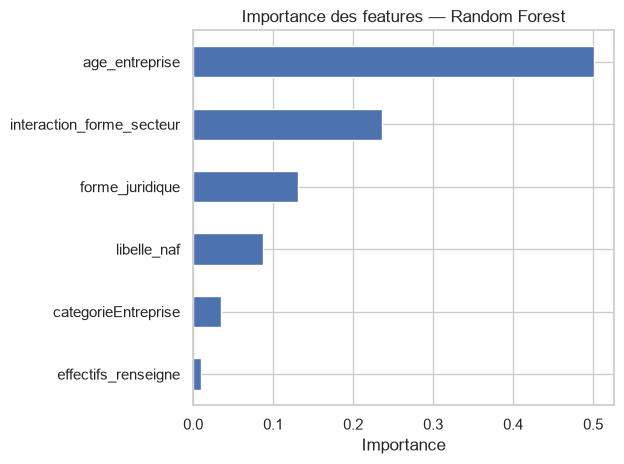

In [16]:
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

fig, ax = plt.subplots()
importances.plot.barh(ax=ax)
ax.invert_yaxis()
ax.set_title("Importance des features — Random Forest")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

Les variables les plus utilisées sont le secteur et l'interaction forme × secteur, puis l'âge.

## XGBoost

In [17]:
scale = (y_train_sample == 0).sum() / (y_train_sample == 1).sum()
print("scale_pos_weight :", round(scale, 1))

scale_pos_weight : 36.3


In [18]:
xgb = XGBClassifier(
    n_estimators=200,
    scale_pos_weight=scale,
    learning_rate=0.1,
    n_jobs=-1,
    random_state=42,
    eval_metric="auc"
)

xgb.fit(X_train_sample, y_train_sample)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [19]:
y_pred_xgb = xgb.predict(X_test)
y_proba_xgb = xgb.predict_proba(X_test)[:, 1]

auc_xgb = roc_auc_score(y_test, y_proba_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)

print(classification_report(y_test, y_pred_xgb, target_names=["Saine", "Défaillante"]))
print("AUC:", auc_xgb)

              precision    recall  f1-score   support

       Saine       1.00      0.81      0.89   3286997
 Défaillante       0.11      0.86      0.19     89933

    accuracy                           0.81   3376930
   macro avg       0.55      0.83      0.54   3376930
weighted avg       0.97      0.81      0.87   3376930

AUC: 0.9115141741681898


In [21]:

os.makedirs("../models", exist_ok=True)
joblib.dump(xgb, "../models/xgboost_defaillance.joblib")
print("Modèle sauvegardé dans models/xgboost_defaillance.joblib")

Modèle sauvegardé dans models/xgboost_defaillance.joblib


XGBoost donne les meilleurs résultats : AUC de 0,91 et 86 % des défaillantes détectées. Le paramètre scale_pos_weight (environ 37) sert à compenser le fait qu'il y a beaucoup plus d'entreprises saines que défaillantes. C'est le modèle qu'on garde.

## Comparaison des modèles

In [22]:
resultats = pd.DataFrame({
    "Modèle": ["Régression logistique", "Random Forest", "XGBoost"],
    "AUC-ROC": [auc_lr, auc_rf, auc_xgb],
    "F1": [f1_lr, f1_rf, f1_xgb],
    "Recall": [recall_lr, recall_rf, recall_xgb],
})
resultats.set_index("Modèle").round(2)

,AUC-ROC,F1,Recall
Modèle,,,
Régression logistique,0.86,0.18,0.82
Random Forest,0.81,0.27,0.40
XGBoost,0.91,0.19,0.86


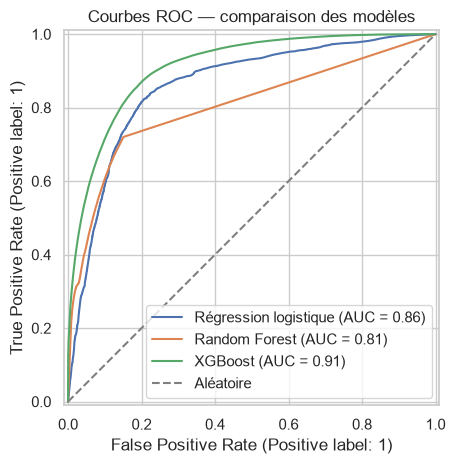

In [23]:
fig, ax = plt.subplots()

RocCurveDisplay.from_predictions(y_test, y_proba_lr, name="Régression logistique", ax=ax)
RocCurveDisplay.from_predictions(y_test, y_proba_rf, name="Random Forest", ax=ax)
RocCurveDisplay.from_predictions(y_test, y_proba_xgb, name="XGBoost", ax=ax)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aléatoire")
ax.set_title("Courbes ROC — comparaison des modèles")
ax.legend()
plt.tight_layout()
plt.show()

XGBoost est le meilleur à la fois en AUC (0,91) et en détection (86 %). La régression logistique reste proche en AUC (0,86), et la Random Forest décroche sur ces deux critères. La Random Forest a bien le meilleur F1 (0,27), mais c'est trompeur ici : on cherche surtout à détecter le maximum de défaillantes, et sur ce point c'est elle la plus faible. On garde donc XGBoost.

## Résultats — analyse de XGBoost

In [24]:
resultats = test[["siren", "age_entreprise", "defaillance"]]

resultats["secteur"] = test["activitePrincipaleUniteLegale"].str[:2].map(LIBELLES_NAF).fillna("Autre")
resultats["forme_juridique"] = test["categorieJuridiqueUniteLegale"].apply(categoriser_juridique)
resultats["categorie"] = test["categorieEntreprise"].fillna("Non renseigné")
resultats["proba"] = y_proba_xgb

resultats.shape

(3376930, 7)

On regarde de plus près ce que donne XGBoost sur le jeu de test.

### Importance des features

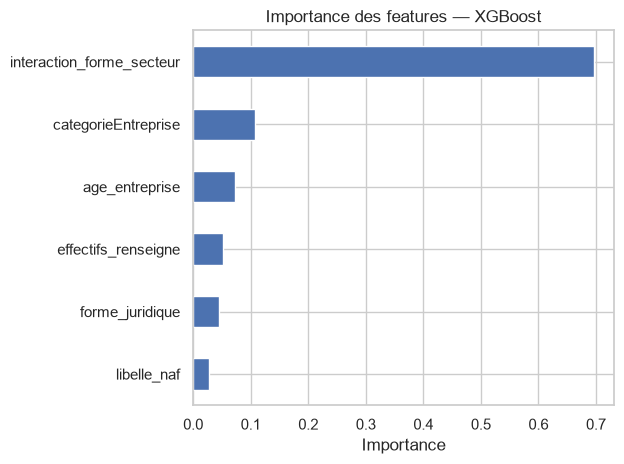

In [25]:
importances_xgb = pd.Series(xgb.feature_importances_, index=features).sort_values(ascending=False)

fig, ax = plt.subplots()
importances_xgb.plot.barh(ax=ax)
ax.invert_yaxis()
ax.set_title("Importance des features — XGBoost")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

Comme pour la Random Forest, le modèle s'appuie surtout sur le secteur et l'interaction forme × secteur. L'âge joue un rôle plus limité.

### Top entreprises les plus à risque

In [26]:
resultats.sort_values("proba", ascending=False).head()

,siren,age_entreprise,defaillance,secteur,forme_juridique,categorie,proba
13481763,920227253,1.248460,True,Imprimerie,SAS,PME,0.999915
13201491,914223193,1.336071,True,Entreposage,SARL,PME,0.999909
15249054,949003826,1.415469,True,Imprimerie,SAS,PME,0.999903
13535956,921031563,0.865161,True,Restauration,SAS,PME,0.999897
15612269,978370682,0.873374,True,Restauration,SAS,PME,0.999897


Les entreprises les mieux classées sont de très jeunes entreprises (moins de 2 ans) dans des secteurs à risque, avec des scores quasiment identiques (autour de 0,9998). Deux choses à retenir : le modèle note surtout selon le profil (secteur, forme, âge) et pas vraiment entreprise par entreprise ; et ces scores proches de 1 ne sont pas de vraies probabilités, ils sont gonflés par scale_pos_weight. On les lit comme un score de risque relatif, pas comme une vraie probabilité de défaut.

### Profil des entreprises flaggées

In [27]:
resultats["flagged"] = resultats["proba"] >= 0.5

flagged = resultats[resultats["flagged"]]

print("Flaggées :", len(flagged))
print()
print(flagged["secteur"].value_counts().head(10))
print()
print(flagged["forme_juridique"].value_counts())
print()
print("Age moyen flaggées :", resultats[resultats["flagged"]]["age_entreprise"].mean().round(1))
print("Age moyen non flaggées :", resultats[resultats["flagged"]==False]["age_entreprise"].mean().round(1))

Flaggées : 705151

secteur
Travaux spécialisés      99225
Commerce détail          84013
Restauration             78064
Direction entreprises    40561
Commerce gros            39899
Immobilier               30862
Commerce auto            24176
Finance                  22798
Services personnels      22410
Transport terrestre      21108
Name: count, dtype: int64

forme_juridique
SARL                       342100
SAS                        271660
Entrepreneur individuel     55907
Autre                       16233
Société civile              11829
Association                  7350
SA                             71
Syndicat/GIE                    1
Name: count, dtype: int64

Age moyen flaggées : 13.6
Age moyen non flaggées : 16.7


Le modèle signale environ 705 000 entreprises, soit presque une sur cinq du jeu de test. Ce sont surtout des entreprises des secteurs déjà repérés comme risqués (travaux spécialisés, restauration, commerce) et des SARL / SAS. L'âge moyen des signalées (13,6 ans) est plus bas que celui des autres (16,7 ans), ce qui colle avec le constat que les entreprises font souvent défaut jeunes.

### KPIs

In [28]:
vp = (resultats["flagged"] & resultats["defaillance"]).sum()
fp = (resultats["flagged"] & (resultats["defaillance"] == False)).sum()
fn = ((resultats["flagged"] == False) & resultats["defaillance"]).sum()

print("Vrais positifs :", vp)
print("Faux positifs :", fp)
print("Ratées :", fn)
print()
print("Détection :", round(vp / resultats["defaillance"].sum() * 100, 1), "%")
print("Précision :", round(vp / resultats["flagged"].sum() * 100, 1), "%")
print("AUC :", round(auc_xgb, 3))

Vrais positifs : 77377
Faux positifs : 627774
Ratées : 12556

Détection : 86.0 %
Précision : 11.0 %
AUC : 0.912


Le modèle détecte 86 % des entreprises qui font réellement défaut, mais avec une précision de seulement 11 % (environ 628 000 fausses alertes). C'est un choix assumé : pour du risque crédit, rater une entreprise qui va faire défaut coûte plus cher qu'une fausse alerte, donc on préfère sur-signaler. Le seuil de 0,5 reste discutable et pourrait être ajusté selon le coût réel.

### Distribution des scores

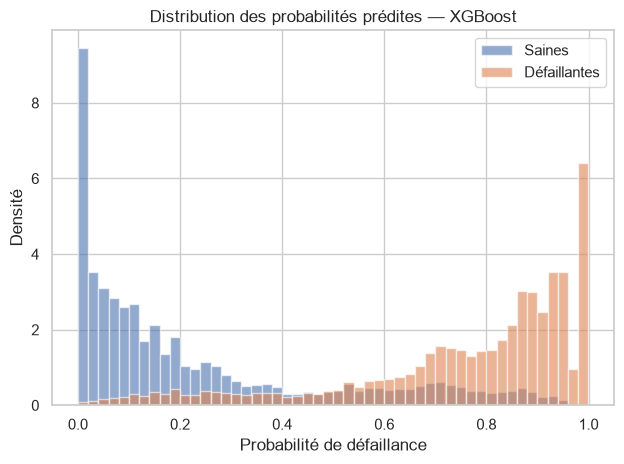

In [29]:
fig, ax = plt.subplots()

ax.hist(y_proba_xgb[y_test == False], bins=50, alpha=0.6, label="Saines", density=True)
ax.hist(y_proba_xgb[y_test == True], bins=50, alpha=0.6, label="Défaillantes", density=True)

ax.set_title("Distribution des probabilités prédites — XGBoost")
ax.set_xlabel("Probabilité de défaillance")
ax.set_ylabel("Densité")
ax.legend()
plt.tight_layout()
plt.show()

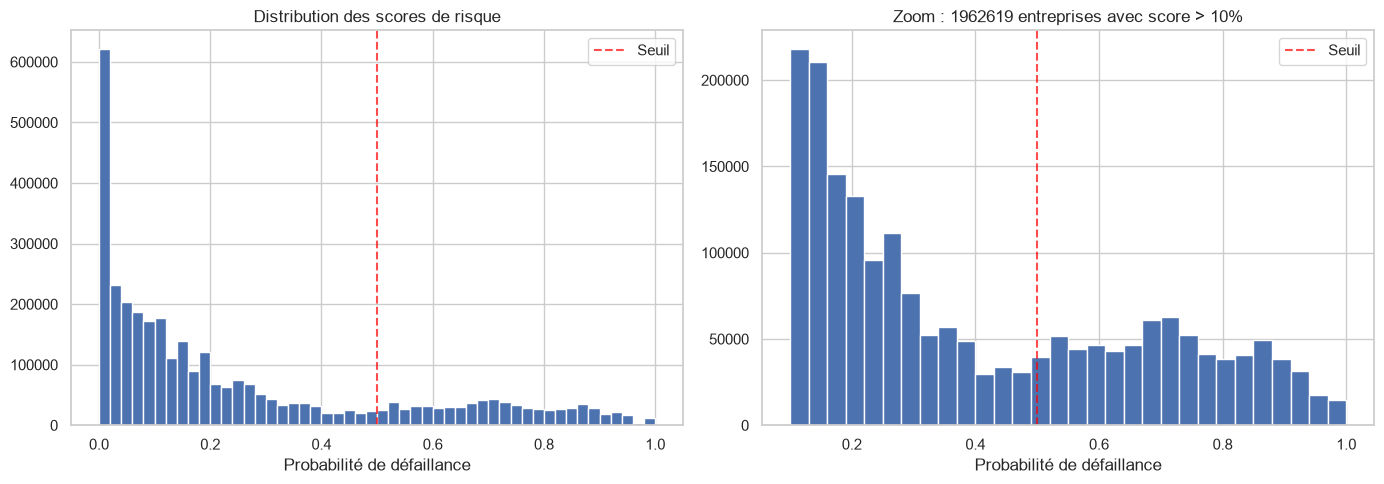

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(resultats["proba"], bins=50)
axes[0].axvline(x=0.5, color="red", linestyle="--", alpha=0.7, label="Seuil")
axes[0].set_title("Distribution des scores de risque")
axes[0].set_xlabel("Probabilité de défaillance")
axes[0].legend()

high_risk = resultats[resultats["proba"] > 0.1]
axes[1].hist(high_risk["proba"], bins=30)
axes[1].axvline(x=0.5, color="red", linestyle="--", alpha=0.7, label="Seuil")
axes[1].set_title(f"Zoom : {len(high_risk)} entreprises avec score > 10%")
axes[1].set_xlabel("Probabilité de défaillance")
axes[1].legend()

plt.tight_layout()
plt.show()

Les scores des défaillantes sont décalés vers la droite par rapport aux saines, mais les deux distributions se recouvrent beaucoup. C'est ce qui explique la faible précision : le modèle sépare en moyenne, mais pas nettement.

## Synthèse

Modèle retenu : XGBoost, pour son meilleur compromis entre AUC (0,91) et détection des défaillantes (86 %).

Ce qu'il sait faire : classer les entreprises par niveau de risque. Il peut donc servir d'outil de priorisation, pour repérer les entreprises à surveiller en premier.

Ses limites et les pistes d'amélioration :
- les probabilités ne sont pas calibrées (étape suivante : une calibration type isotonic ou Platt)
- beaucoup de fausses alertes (précision de 11 %)
- le modèle note par profil plus que par entreprise
- il n'utilise que des données structurelles ; ajouter les ratios financiers (INPI) serait la vraie piste d'amélioration